# 06 · Q3 — Adakah kota yang kenaikan harganya mendahului kota lain? Berapa jedanya?

**Keputusan yang didukung:** kota mana yang dijadikan sinyal dini.

**Metode** (`src/analysis/leadlag.py`, `config.analisis.q3_leadlag`):
1. Uji stasioneritas (ADF) log-return mingguan — syarat korelasi silang & Granger.
2. **Prewhitening**: buang momentum tiap kota (regresi pada lag-nya sendiri 1–4 minggu). Alasan ada di §1.
3. Korelasi silang berjeda 1–4 minggu antara kejutan harga satu kota dan rata-rata kota lain ("pasar"), koreksi
   Benjamini–Hochberg, syarat korelasi ≥ 0,15 dan lebih kuat daripada arah sebaliknya.
4. Granger causality hanya sebagai pendukung.

**Penting:** ini asosiasi statistik. Korelasi berjeda dan Granger **bukan** bukti bahwa harga di satu kota menyebabkan
kenaikan di kota lain. Jalankan sel analisis butuh ±2–3 menit (ribuan pasangan kota diuji).

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import leadlag as L
res = L.run(cfg)

## 1. Kenapa momentum harus dibuang dulu?
Perubahan harga mingguan punya **momentum** (naik minggu ini → cenderung naik minggu depan) dan antar kota **bergerak
bersamaan**. Gabungan keduanya membuat korelasi berjeda tampak tinggi untuk hampir semua pasangan kota, sehingga
"semua kota mendahului semua kota". Kolom "semu" menunjukkan berapa pasangan yang tampak mendahului jika momentum tidak
dibuang; kolom berikutnya setelah dibuang.

In [2]:
res["kom"][["kualitas", "kota", "porsi_seri_stasioner_adf", "autokorelasi_lag1_median", "korelasi_lag0_median",
            "pasangan_mendahului_semu", "pasangan_mendahului_setelah_prewhitening", "kota_penentu_arah", "kota_pengikut",
            "jeda_dominan_minggu"]]

,kualitas,kota,porsi_seri_stasioner_adf,autokorelasi_lag1_median,korelasi_lag0_median,pasangan_mendahului_semu,pasangan_mendahului_setelah_prewhitening,kota_penentu_arah,kota_pengikut,jeda_dominan_minggu
0,Cabai Rawit Merah,35,1.000,0.291,0.781,607,247,3,9,1
1,Cabai Merah Keriting,32,1.000,0.082,0.685,381,214,9,8,1
2,Bawang Merah Ukuran Sedang,35,1.000,0.301,0.573,628,507,17,18,1
3,Bawang Putih Ukuran Sedang,35,0.971,0.085,0.262,312,266,20,12,1
4,Daging Ayam Ras Segar,35,1.000,0.034,0.617,330,289,10,17,1
5,Telur Ayam Ras Segar,35,1.000,0.170,0.665,570,221,6,14,1


## 2. Kota penentu arah (3 teratas per komoditas)

In [3]:
pr = res["peran"]
(pr[pr.peran == "penentu arah"].sort_values("korelasi", ascending=False).groupby("kualitas").head(3)
   [["kualitas", "kota", "provinsi", "jeda", "korelasi", "kekuatan", "granger_mendukung"]])

,kualitas,kota,provinsi,jeda,korelasi,kekuatan,granger_mendukung
97,Bawang Merah Ukuran Sedang,Kota Surakarta (Solo),Jawa Tengah,1.000,0.508,kuat,True
98,Bawang Merah Ukuran Sedang,Kota Tangerang,Banten,1.000,0.475,kuat,True
70,Bawang Merah Ukuran Sedang,Kab. Cilacap,Jawa Tengah,1.000,0.470,kuat,True
135,Bawang Putih Ukuran Sedang,Kota Tegal,Jawa Tengah,1.000,0.451,kuat,True
132,Bawang Putih Ukuran Sedang,Kota Surakarta (Solo),Jawa Tengah,1.000,0.442,kuat,True
107,Bawang Putih Ukuran Sedang,Kab. Jember,Jawa Timur,1.000,0.405,kuat,True
159,Daging Ayam Ras Segar,Kota Kediri,Jawa Timur,1.000,0.342,kuat,True
162,Daging Ayam Ras Segar,Kota Probolinggo,Jawa Timur,1.000,0.323,kuat,True
149,Daging Ayam Ras Segar,Kab. Tasikmalaya,Jawa Barat,1.000,0.318,kuat,True
198,Telur Ayam Ras Segar,Kota Semarang,Jawa Tengah,1.000,0.310,kuat,True


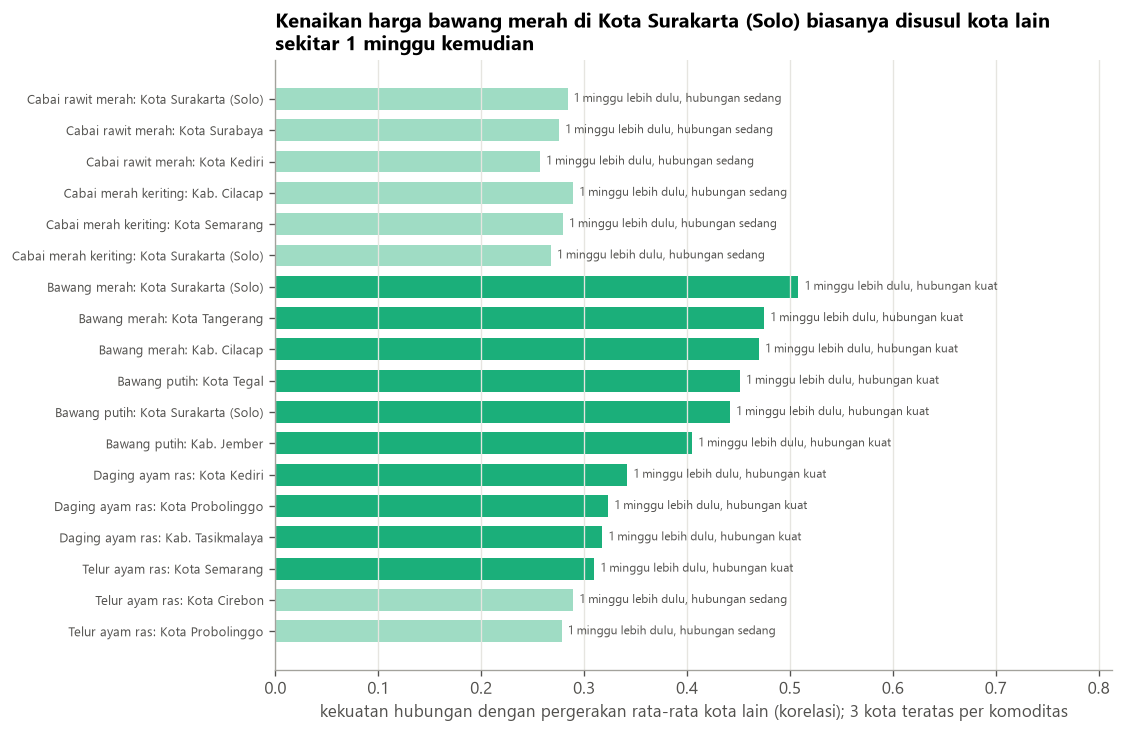

In [4]:
figs = L.figures(res, cfg)
gambar(figs["penentu"])

## 3. Arah penyebaran per provinsi
Positif = provinsi yang harganya biasanya naik lebih dulu; negatif = menyusul.

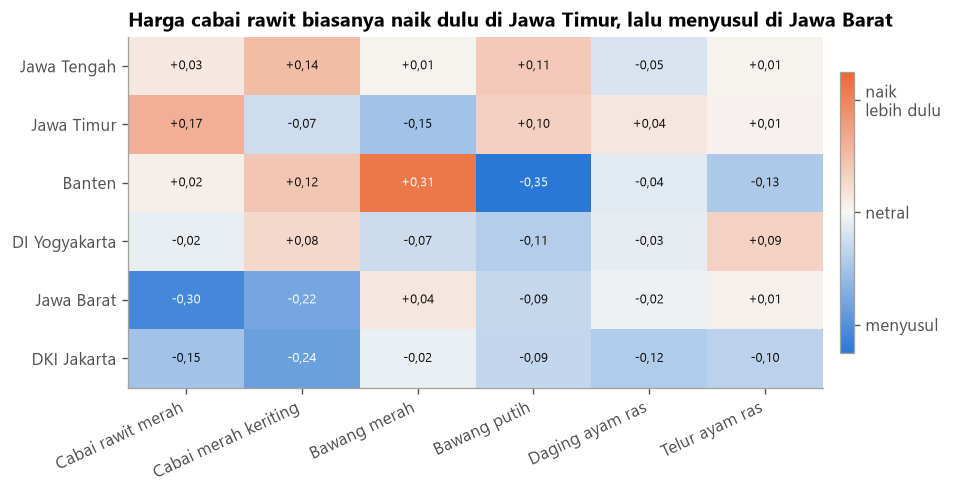

In [5]:
gambar(figs["provinsi"])

## 4. Untuk kota tujuan distributor: kota mana yang perlu dipantau?

In [6]:
res["tujuan"][res["tujuan"].kota_tujuan.isin(["Kota Jakarta Pusat", "Kota Bandung"])].sort_values(
    ["kota_tujuan", "kualitas", "korelasi"], ascending=[True, True, False])

,kualitas,kota_tujuan,pantau_kota,provinsi,jeda,korelasi,kekuatan
18,Bawang Merah Ukuran Sedang,Kota Bandung,Kab. Cilacap,Jawa Tengah,1,0.372,kuat
19,Bawang Merah Ukuran Sedang,Kota Bandung,Kota Surabaya,Jawa Timur,1,0.335,kuat
20,Bawang Merah Ukuran Sedang,Kota Bandung,Kab. Karanganyar,Jawa Tengah,1,0.306,kuat
30,Bawang Putih Ukuran Sedang,Kota Bandung,Kota Serang,Banten,1,0.292,sedang
31,Bawang Putih Ukuran Sedang,Kota Bandung,Kota Tegal,Jawa Tengah,2,0.266,sedang
32,Bawang Putih Ukuran Sedang,Kota Bandung,Kota Cirebon,Jawa Barat,2,0.250,sedang
9,Cabai Merah Keriting,Kota Bandung,Kab. Klaten,Jawa Tengah,1,0.410,kuat
10,Cabai Merah Keriting,Kota Bandung,Kota Tangerang,Banten,1,0.395,kuat
11,Cabai Merah Keriting,Kota Bandung,Kab. Cilacap,Jawa Tengah,1,0.393,kuat
3,Cabai Rawit Merah,Kota Bandung,Kota Serang,Banten,1,0.490,kuat


## 5. Seberapa besar pengaruhnya?
Bandingkan korelasi "bergerak di minggu yang sama" dengan korelasi "mendahului": untuk hampir semua komoditas harga
lebih banyak bergerak bersamaan, sehingga sinyal dari kota lain hanya menambah sekitar 1 minggu waktu antisipasi.

In [7]:
lead = pr[pr.peran == "penentu arah"].groupby("kualitas").korelasi.median().rename("korelasi mendahului (median)")
res["kom"].set_index("kualitas")[["korelasi_lag0_median"]].join(lead)

,korelasi_lag0_median,korelasi mendahului (median)
kualitas,,
Cabai Rawit Merah,0.781,0.276
Cabai Merah Keriting,0.685,0.266
Bawang Merah Ukuran Sedang,0.573,0.396
Bawang Putih Ukuran Sedang,0.262,0.284
Daging Ayam Ras Segar,0.617,0.289
Telur Ayam Ras Segar,0.665,0.277


### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [8]:
L.write_summary(res, figs, cfg)
tampilkan_temuan("q3_kota_penentu_arah.md")

**Kenaikan harga bawang merah di Kota Surakarta (Solo) biasanya disusul kota lain sekitar 1 minggu kemudian** (hubungan kuat). Untuk cabai rawit, kota yang harganya biasanya naik lebih dulu: Kota Surakarta (Solo), Kota Surabaya, Kota Kediri; kota di Jawa Barat dan DKI Jakarta cenderung menyusul. Tindakan: pantau harga di kota penentu arah setiap minggu; kenaikan di sana adalah sinyal untuk mengamankan stok di kota tujuan sekitar 1 minggu sebelum harga di sana ikut naik.